# 🔩 NEU-STEEL: CNN-Based Micro-Crack Detection in Steel Plates

**Course Project – EST Evaluation**  
**Thapar Institute of Engineering and Technology**

---

## Problem Statement
Tata Steel Ltd. is automating quality inspection in its manufacturing process. This project develops a CNN-based image recognition system capable of detecting micro-level surface cracks and defects in steel plates using a **simple CNN trained from scratch** with data augmentation, Grad-CAM visualisation, and a live Gradio inspection portal.

---

## Dataset
**NEU Surface Defect Database (NEU-DET)**
- 1,800 total images across 6 defect classes
- Train/Val/Test: 70 / 15 / 15 stratified split
- Classes: `crazing`, `inclusion`, `patches`, `pitted_surface`, `rolled-in_scale`, `scratches`

---

## Pipeline
Dataset → EDA → Augmentation → SimpleCNN → Training → Evaluation → **Grad-CAM** → **Live Portal**

## Section 0 – Setup & Installations

In [1]:
!pip install albumentations torchinfo grad-cam gradio -q
print('Done')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 67.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Done


In [2]:
import os, re, time, warnings, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary

import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, f1_score,
    accuracy_score
)
from sklearn.preprocessing import label_binarize
import cv2

# ── Reproducibility ──
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


## Section 1 – Dataset Loading

Upload `archive.zip` to Colab (`/content/`), then run the cell below.  
The dataset has a flat structure – class name is embedded in each filename (e.g. `crazing_10.jpg`).

In [3]:
import os

os.environ['KAGGLE_TOKEN'] = 'KGAT_d759106aa8d41d412ddbaf5741cee616'

!pip install kaggle -q
!kaggle datasets download -d kaustubhdikshit/neu-surface-defect-database
os.rename('/content/neu-surface-defect-database.zip', '/content/archive.zip')

import zipfile
with zipfile.ZipFile('/content/archive.zip', 'r') as z:
    z.extractall('/content/neu_steel')

print('Done! Dataset ready.')

Dataset URL: https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database
License(s): unknown
100% 26.4M/26.4M [00:00<00:00, 186MB/s] 

Done! Dataset ready.


In [4]:
import os, re, zipfile
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# â”€â”€ Extract if needed â”€â”€
EXTRACT_PATH = '/content/neu_steel'
ZIP_PATH = '/content/archive.zip'

if not os.path.exists(EXTRACT_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_PATH)
    print(' Extracted.')
else:
    print(' Already extracted.')

# â”€â”€ Find images â”€â”€
def get_class_from_filename(fname):
    stem = Path(fname).stem
    return re.sub(r'_\d+$', '', stem)

def build_df(folder):
    records = []
    for p in sorted(Path(folder).rglob('*.jpg')):
        cls = get_class_from_filename(p.name)
        records.append({'path': str(p), 'label': cls})
    return pd.DataFrame(records)

df_all = build_df(EXTRACT_PATH)
print(f'Total images found: {len(df_all)}')
print(df_all['label'].value_counts())

# â”€â”€ Classes â”€â”€
CLASSES      = sorted(df_all['label'].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES  = len(CLASSES)
df_all['label_idx'] = df_all['label'].map(CLASS_TO_IDX)
print(f'Classes ({NUM_CLASSES}): {CLASSES}')

# â”€â”€ Stratified 70/15/15 Split â”€â”€
df_trainval, df_test = train_test_split(
    df_all, test_size=0.15, stratify=df_all['label_idx'], random_state=SEED
)
df_train, df_val = train_test_split(
    df_trainval, test_size=15/85, stratify=df_trainval['label_idx'], random_state=SEED
)
df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print(f'Train : {len(df_train)} ({len(df_train)/len(df_all)*100:.1f}%)')
print(f'Val   : {len(df_val)} ({len(df_val)/len(df_all)*100:.1f}%)')
print(f'Test  : {len(df_test)} ({len(df_test)/len(df_all)*100:.1f}%)')

# â”€â”€ Class weights â”€â”€
counts = df_train['label_idx'].value_counts().sort_index().values
cw     = 1.0 / counts
CLASS_WEIGHTS = torch.FloatTensor(cw / cw.sum() * NUM_CLASSES).to(DEVICE)
print(f'Class weights: {CLASS_WEIGHTS.cpu().numpy().round(3)}')
print('… All done!')

 Already extracted.
Total images found: 1800
label
crazing            300
inclusion          300
patches            300
pitted_surface     300
rolled-in_scale    300
scratches          300
Name: count, dtype: int64
Classes (6): ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Train : 1260 (70.0%)
Val   : 270 (15.0%)
Test  : 270 (15.0%)
Class weights: [1. 1. 1. 1. 1. 1.]
… All done!


## Section 2 â€” Exploratory Data Analysis

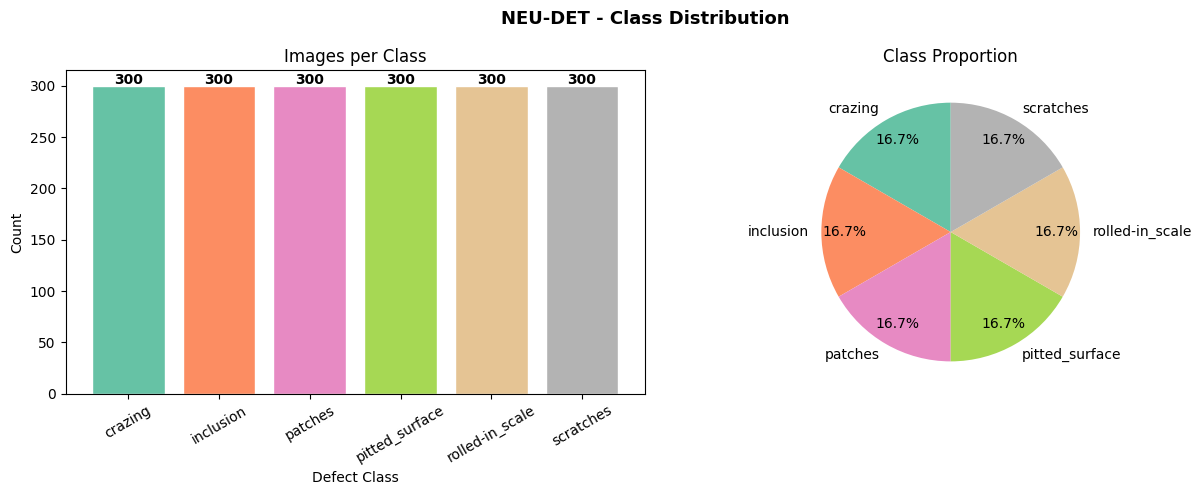

In [5]:
# â”€â”€ 2.1 Class Distribution â”€â”€
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('NEU-DET - Class Distribution', fontsize=13, fontweight='bold')

counts_plot = df_all['label'].value_counts()
colors      = plt.cm.Set2(np.linspace(0, 1, NUM_CLASSES))

axes[0].bar(counts_plot.index, counts_plot.values, color=colors, edgecolor='white')
axes[0].set_title('Images per Class')
axes[0].set_xlabel('Defect Class')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(counts_plot.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

axes[1].pie(counts_plot.values, labels=counts_plot.index, autopct='%1.1f%%',
            colors=colors, startangle=90, pctdistance=0.82)
axes[1].set_title('Class Proportion')

plt.tight_layout()
plt.savefig('/content/eda_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

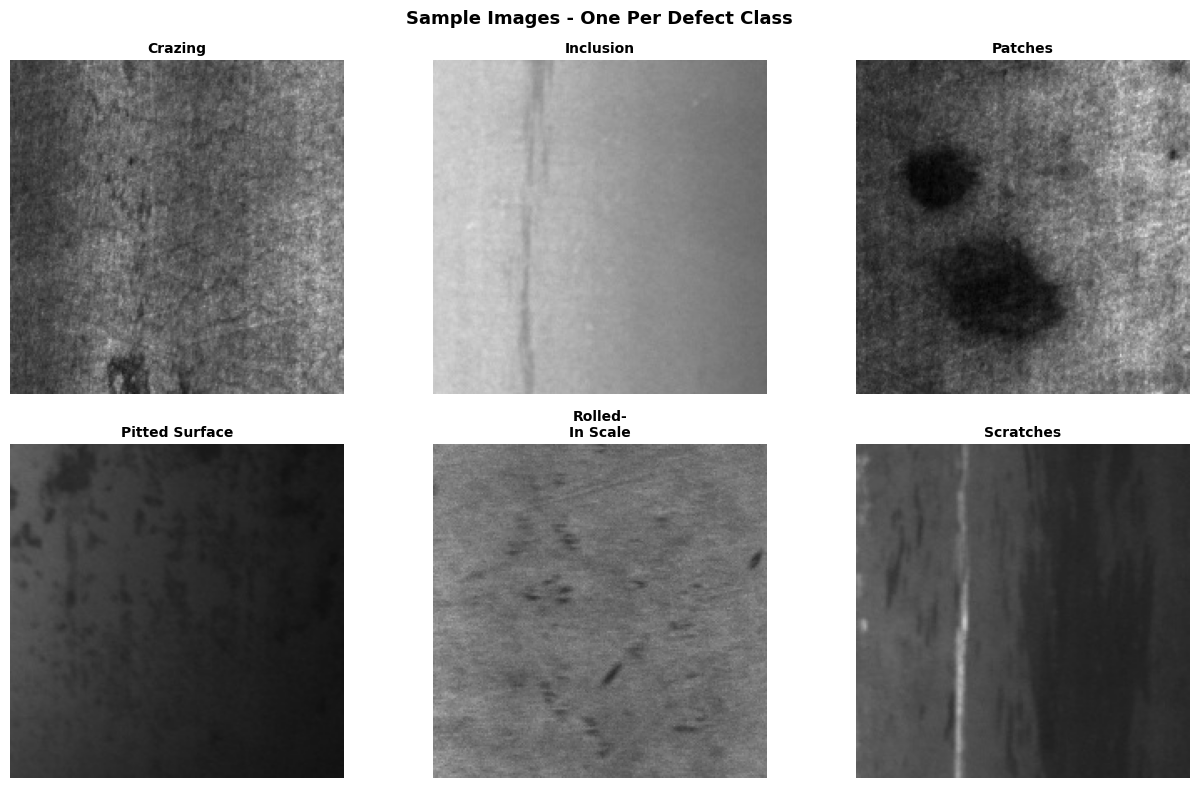

In [6]:
# â”€â”€ 2.2 Sample Images Grid â”€â”€
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
fig.suptitle('Sample Images - One Per Defect Class', fontsize=13, fontweight='bold')

for ax, cls in zip(axes.flatten(), CLASSES):
    sample = df_all[df_all['label'] == cls].sample(1).iloc[0]
    img    = Image.open(sample['path']).convert('RGB')
    ax.imshow(img)
    ax.set_title(cls.replace('_', ' ').replace('-', '-\n').title(), fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/eda_sample_grid.png', dpi=150, bbox_inches='tight')
plt.show()

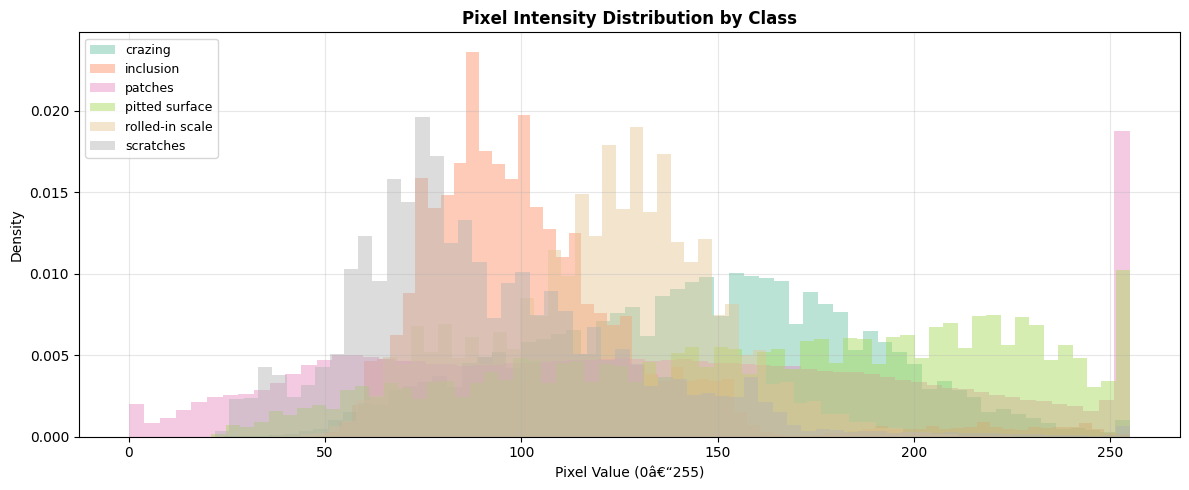

In [7]:
# â”€â”€ 2.3 Pixel Intensity Distribution per Class â”€â”€
fig, ax = plt.subplots(figsize=(12, 5))

for cls, color in zip(CLASSES, colors):
    cls_df    = df_all[df_all['label'] == cls]
    # FIX #9: min(25, len(cls_df)) â€” previously min(25,300) was always 25 but misleading
    sample_df = cls_df.sample(min(25, len(cls_df)))
    pixels    = []
    for _, row in sample_df.iterrows():
        arr = np.array(Image.open(row['path']).convert('L'))
        pixels.extend(arr.flatten().tolist())
    ax.hist(pixels, bins=64, alpha=0.45, label=cls.replace('_', ' '), color=color, density=True)

ax.set_title('Pixel Intensity Distribution by Class', fontsize=12, fontweight='bold')
ax.set_xlabel('Pixel Value (0â€“255)')
ax.set_ylabel('Density')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/content/eda_pixel_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# â”€â”€ 2.4 Image Statistics â”€â”€
print('Image statistics (sample of 60 images):')
sample_paths = df_all.sample(60)['path'].tolist()
sizes   = [Image.open(p).size for p in sample_paths]
widths  = [s[0] for s in sizes]
heights = [s[1] for s in sizes]
print(f'  Width  - min:{min(widths)} max:{max(widths)} mean:{np.mean(widths):.0f}')
print(f'  Height - min:{min(heights)} max:{max(heights)} mean:{np.mean(heights):.0f}')
print(f'  All images consistent: {len(set(sizes)) == 1}')

print('\nMean pixel intensity per class:')
for cls in CLASSES:
    samp  = df_all[df_all['label'] == cls].sample(min(20, len(df_all[df_all['label']==cls])))
    means = [np.array(Image.open(r['path']).convert('L')).mean() for _, r in samp.iterrows()]
    print(f'  {cls:<22}: mean={np.mean(means):.1f}  std={np.std(means):.1f}')

Image statistics (sample of 60 images):
  Width  - min:200 max:200 mean:200
  Height - min:200 max:200 mean:200
  All images consistent: True

Mean pixel intensity per class:
  crazing               : mean=142.1  std=29.1
  inclusion             : mean=100.8  std=28.8
  patches               : mean=144.5  std=35.6
  pitted_surface        : mean=169.8  std=53.5
  rolled-in_scale       : mean=109.4  std=26.7
  scratches             : mean=97.5  std=27.7


## Section 3 â€” Preprocessing & Augmentation

**Preprocessing:** Resize to 224Ã—224, convert to RGB, normalize with ImageNet mean/std.

**Augmentation (train only):**
- Geometric: horizontal/vertical flips, 90Â° rotate, elastic transform, grid distortion
- Photometric: CLAHE (critical for micro-crack contrast), brightness/contrast, Gaussian noise, blur
- Regularization: CoarseDropout (simulates occlusion)

Validation and test sets receive **no augmentation** â€” only resize + normalize.

In [9]:
IMG_SIZE   = 128   # smaller input for a lightweight CNN
BATCH_SIZE = 32
IMG_MEAN   = [0.5, 0.5, 0.5]
IMG_STD    = [0.5, 0.5, 0.5]

train_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.5),
    A.Rotate(limit=30, p=0.4),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    A.GaussianBlur(blur_limit=(3, 7), p=0.2),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, p=0.2),
    A.Normalize(mean=IMG_MEAN, std=IMG_STD),
    ToTensorV2(),
])

val_test_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMG_MEAN, std=IMG_STD),
    ToTensorV2(),
])

print(f'Train augmentations  : {len(train_transforms.transforms)} ops')
print(f'Val/Test transforms  : {len(val_test_transforms.transforms)} ops')

Train augmentations  : 12 ops
Val/Test transforms  : 3 ops


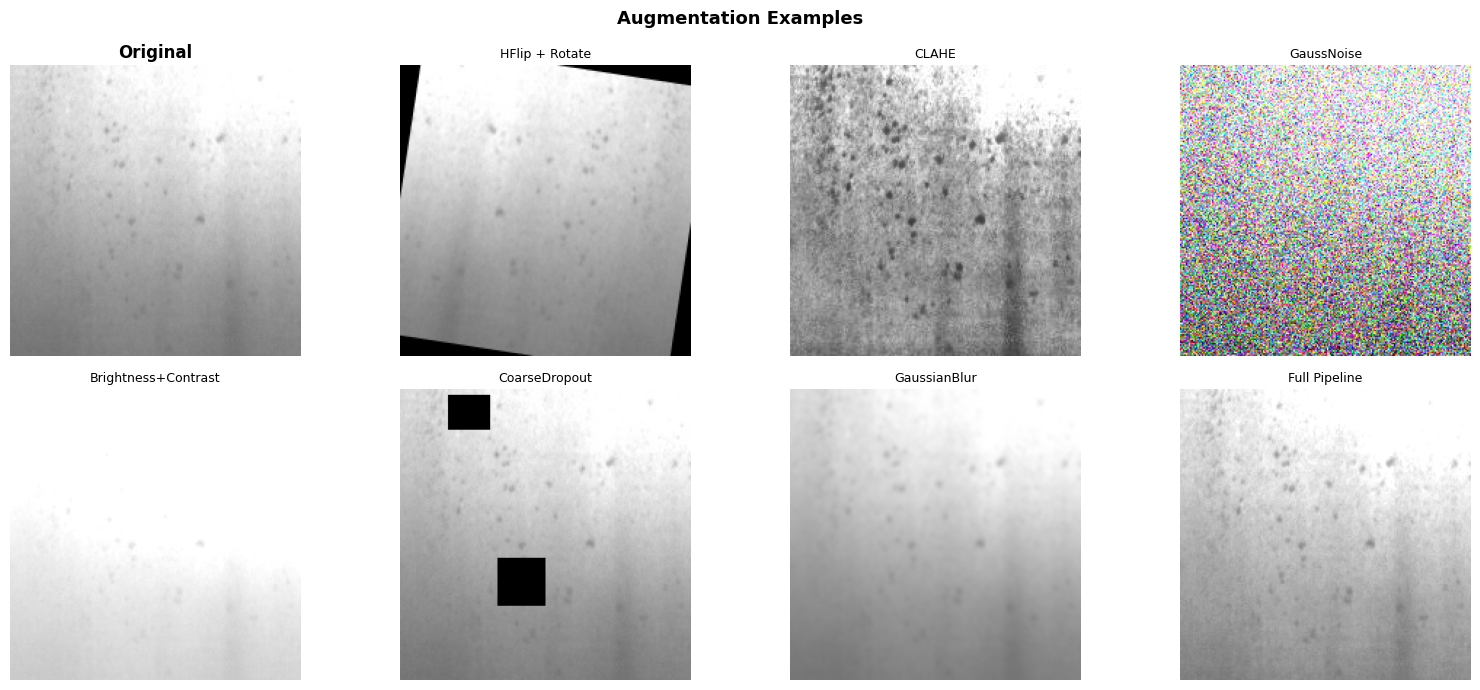

In [10]:
sample_img = np.array(Image.open(df_train.iloc[0]['path']).convert('RGB'))

aug_list = [
    ('HFlip + Rotate',      A.Compose([A.HorizontalFlip(p=1), A.Rotate(limit=30, p=1)])),
    ('CLAHE',               A.CLAHE(clip_limit=6.0, p=1)),
    ('GaussNoise',          A.GaussNoise(var_limit=(40.0, 90.0), p=1)),
    ('Brightness+Contrast', A.RandomBrightnessContrast(0.5, 0.5, p=1)),
    ('CoarseDropout',       A.CoarseDropout(max_holes=12, max_height=20, max_width=20, p=1)),
    ('GaussianBlur',        A.GaussianBlur(blur_limit=(5, 9), p=1)),
    ('Full Pipeline',       A.Compose([A.HorizontalFlip(p=0.5), A.CLAHE(p=0.8),
                                       A.RandomBrightnessContrast(p=0.5)])),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle('Augmentation Examples', fontsize=13, fontweight='bold')
axes[0,0].imshow(sample_img); axes[0,0].set_title('Original', fontweight='bold'); axes[0,0].axis('off')
for idx, (name, aug) in enumerate(aug_list):
    ax = axes[(idx+1)//4][(idx+1)%4]
    ax.imshow(aug(image=sample_img.copy())['image'])
    ax.set_title(name, fontsize=9); ax.axis('off')
plt.tight_layout()
plt.savefig('/content/augmentation_examples.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# â”€â”€ Dataset & DataLoader â”€â”€
class SteelDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = np.array(Image.open(row['path']).convert('RGB'))
        label = int(row['label_idx'])
        if self.transform:
            image = self.transform(image=image)['image']
        return image, label


train_dataset = SteelDataset(df_train, train_transforms)
val_dataset   = SteelDataset(df_val,   val_test_transforms)
test_dataset  = SteelDataset(df_test,  val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

imgs, labels = next(iter(train_loader))
print(f'Train batches  : {len(train_loader)}')
print(f'Val batches    : {len(val_loader)}')
print(f'Batch shape    : {imgs.shape}  labels: {labels.shape}')

Train batches  : 40
Val batches    : 9
Batch shape    : torch.Size([32, 3, 128, 128])  labels: torch.Size([32])


## Section 4 – Model Architecture

We build a **simple custom CNN from scratch** — no pretrained weights, no external backbone.

### SimpleCNN Architecture
- **4 convolutional blocks**: each block has `Conv2d → BatchNorm2d → ReLU → Conv2d → BatchNorm2d → ReLU → MaxPool2d`
- **Filter progression**: 32 → 64 → 128 → 256
- **Classifier head**: `GlobalAvgPool → Dropout → FC(512) → ReLU → Dropout → FC(num_classes)`
- **Total parameters**: ~3–4M — lightweight and trainable on free Colab GPU

This architecture learns discriminative features from 128×128 steel images entirely from scratch.

In [12]:
class SimpleCNN(nn.Module):
    """
    A simple 4-block CNN built from scratch for steel defect classification.
    No pretrained weights. Trained end-to-end on NEU-DET.
    """
    def __init__(self, num_classes=6, dropout=0.4):
        super().__init__()

        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2, 2),
            )

        self.features = nn.Sequential(
            conv_block(3,   32),   # 128 -> 64
            conv_block(32,  64),   # 64  -> 32
            conv_block(64,  128),  # 32  -> 16
            conv_block(128, 256),  # 16  -> 8
        )

        self.pool = nn.AdaptiveAvgPool2d(1)  # 8 -> 1

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(256, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout / 2),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)


# Quick sanity check
_m = SimpleCNN(num_classes=NUM_CLASSES)
_dummy = torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)
print('Output shape:', _m(_dummy).shape)

total_params     = sum(p.numel() for p in _m.parameters())
trainable_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f'Total params    : {total_params/1e6:.2f}M')
print(f'Trainable params: {trainable_params/1e6:.2f}M')

summary(_m, input_size=(1, 3, IMG_SIZE, IMG_SIZE),
        col_names=['input_size', 'output_size', 'num_params'], verbose=0)
del _m

Output shape: torch.Size([2, 6])
Total params    : 1.31M
Trainable params: 1.31M


## Section 5 – Training Engine

In [13]:
class EarlyStopping:
    def __init__(self, patience=7, min_delta=1e-4, path='best.pth'):
        self.patience   = patience
        self.min_delta  = min_delta
        self.path       = path
        self.best_loss  = np.inf
        self.counter    = 0
        self.best_epoch = 0
        self.triggered  = False

    def __call__(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss  = val_loss
            self.best_epoch = epoch
            self.counter    = 0
            torch.save(model.state_dict(), self.path)
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.triggered = True


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out  = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (out.detach().argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        out   = model(imgs)
        loss  = criterion(out, labels)
        probs = torch.softmax(out, 1)
        preds = probs.argmax(1)
        total_loss += loss.item() * imgs.size(0)
        correct    += (preds == labels).sum().item()
        total      += imgs.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
    return (total_loss/total, correct/total,
            np.array(all_preds), np.array(all_labels), np.array(all_probs))


def train_model(model, model_name, save_path, num_epochs=30, lr=1e-3):
    model  = model.to(DEVICE)
    crit   = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
    opt    = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch    = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=num_epochs, eta_min=1e-6)
    es     = EarlyStopping(patience=7, path=save_path + '_best.pth')
    history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}

    print(f'\n' + '='*55)
    print(f'  {model_name} - Training ({num_epochs} epochs max)')
    print('='*55)

    for epoch in range(1, num_epochs + 1):
        t0 = time.time()
        tr_l, tr_a     = train_one_epoch(model, train_loader, opt, crit)
        vl_l, vl_a, *_ = evaluate(model, val_loader, crit)
        sch.step(); es(vl_l, model, epoch)
        history['train_loss'].append(tr_l); history['val_loss'].append(vl_l)
        history['train_acc'].append(tr_a);  history['val_acc'].append(vl_a)
        print(f'  Ep {epoch:02d}/{num_epochs} | Loss {tr_l:.4f}/{vl_l:.4f} | '
              f'Acc {tr_a:.4f}/{vl_a:.4f} | LR {sch.get_last_lr()[0]:.2e} | {time.time()-t0:.1f}s')
        if es.triggered:
            print(f'  Early stop at epoch {epoch} (best: {es.best_epoch})')
            break

    model.load_state_dict(torch.load(save_path + '_best.pth', map_location=DEVICE))
    _, test_acc, test_preds, test_labels, test_probs = evaluate(model, test_loader, crit)
    test_labels_bin = label_binarize(test_labels, classes=list(range(NUM_CLASSES)))
    roc_auc = roc_auc_score(test_labels_bin, test_probs, multi_class='ovr', average='macro')
    f1_mac  = f1_score(test_labels, test_preds, average='macro')
    f1_wt   = f1_score(test_labels, test_preds, average='weighted')

    metrics = {
        'accuracy': test_acc, 'f1_macro': f1_mac, 'f1_weighted': f1_wt,
        'roc_auc': roc_auc, 'preds': test_preds, 'labels': test_labels, 'probs': test_probs
    }

    print(f'\n  {model_name} - Test Acc: {test_acc:.4f} | F1: {f1_mac:.4f} | AUC: {roc_auc:.4f}')
    return model, history, metrics


print('Training engine ready.')

Training engine ready.


## Section 6 – Train the SimpleCNN

> **Note:** Training from scratch typically takes **15–25 min** on a free Colab T4 GPU for 30 epochs.

All parameters are trained simultaneously using **AdamW + CosineAnnealingLR + EarlyStopping**.

In [14]:
cnn_model = SimpleCNN(num_classes=NUM_CLASSES).to(DEVICE)

cnn_model, cnn_history, cnn_metrics = train_model(
    cnn_model, 'SimpleCNN', '/content/simplecnn',
    num_epochs=30, lr=1e-3
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f'GPU memory freed. Allocated: {torch.cuda.memory_allocated()/1e6:.1f} MB')


  SimpleCNN - Training (30 epochs max)
  Ep 01/30 | Loss 1.6997/1.0011 | Acc 0.3048/0.6741 | LR 9.97e-04 | 4.0s
  Ep 02/30 | Loss 1.5561/0.9620 | Acc 0.4024/0.6778 | LR 9.89e-04 | 3.8s
  Ep 03/30 | Loss 1.4494/1.6593 | Acc 0.4405/0.4444 | LR 9.76e-04 | 3.6s
  Ep 04/30 | Loss 1.3434/0.7474 | Acc 0.4913/0.7630 | LR 9.57e-04 | 3.2s
  Ep 05/30 | Loss 1.2788/0.8830 | Acc 0.5056/0.7111 | LR 9.33e-04 | 3.2s
  Ep 06/30 | Loss 1.1418/0.6987 | Acc 0.5516/0.7926 | LR 9.05e-04 | 4.3s
  Ep 07/30 | Loss 1.0144/0.5462 | Acc 0.6071/0.8259 | LR 8.72e-04 | 3.1s
  Ep 08/30 | Loss 1.0213/0.5109 | Acc 0.6198/0.8148 | LR 8.35e-04 | 3.2s
  Ep 09/30 | Loss 0.9392/0.6525 | Acc 0.6278/0.6963 | LR 7.94e-04 | 3.1s
  Ep 10/30 | Loss 0.9276/0.4747 | Acc 0.6540/0.8778 | LR 7.50e-04 | 4.2s
  Ep 11/30 | Loss 0.8772/0.4248 | Acc 0.6651/0.8556 | LR 7.04e-04 | 3.2s
  Ep 12/30 | Loss 0.8153/0.3736 | Acc 0.6841/0.8444 | LR 6.55e-04 | 3.1s
  Ep 13/30 | Loss 0.8026/0.3593 | Acc 0.6944/0.9074 | LR 6.04e-04 | 3.1s
  Ep 14/30 

## Section 7 – Evaluation & Results

In [15]:
# 7.1 Metrics Summary
print('='*55)
print('  SimpleCNN - TEST SET RESULTS')
print('='*55)
print(f'  Accuracy   : {cnn_metrics["accuracy"]*100:.2f}%')
print(f'  Macro F1   : {cnn_metrics["f1_macro"]*100:.2f}%')
print(f'  Weighted F1: {cnn_metrics["f1_weighted"]*100:.2f}%')
print(f'  ROC-AUC    : {cnn_metrics["roc_auc"]:.4f}')
print('='*55)

  SimpleCNN - TEST SET RESULTS
  Accuracy   : 97.04%
  Macro F1   : 97.03%
  Weighted F1: 97.03%
  ROC-AUC    : 0.9978


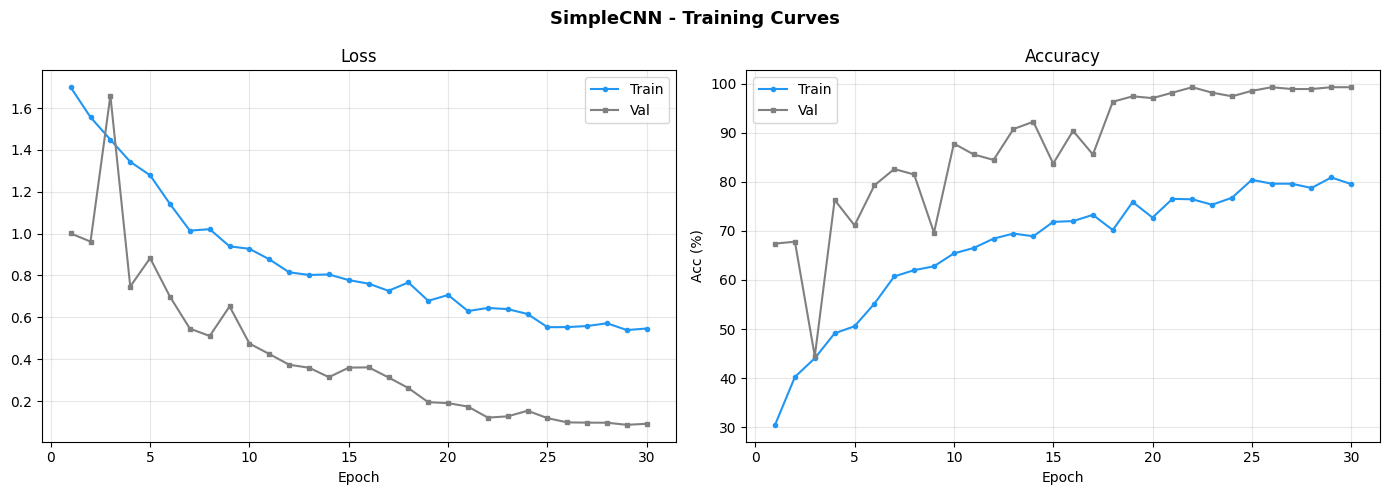

In [16]:
# 7.2 Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SimpleCNN - Training Curves', fontsize=13, fontweight='bold')

eps = range(1, len(cnn_history['train_loss']) + 1)

axes[0].plot(eps, cnn_history['train_loss'], '-o', markersize=3, color='#2196F3', label='Train')
axes[0].plot(eps, cnn_history['val_loss'],   '-s', markersize=3, color='gray',    label='Val')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(eps, [a*100 for a in cnn_history['train_acc']], '-o', markersize=3, color='#2196F3', label='Train')
axes[1].plot(eps, [a*100 for a in cnn_history['val_acc']],   '-s', markersize=3, color='gray',    label='Val')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Acc (%)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

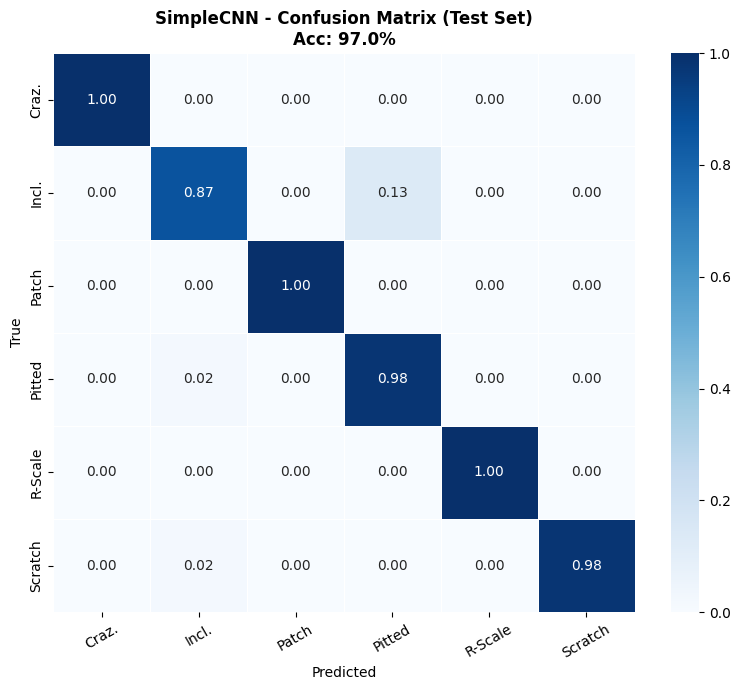

In [17]:
# 7.3 Confusion Matrix
LABEL_ABBREV = {
    'crazing':        'Craz.',
    'inclusion':      'Incl.',
    'patches':        'Patch',
    'pitted_surface': 'Pitted',
    'rolled-in_scale':'R-Scale',
    'scratches':      'Scratch',
}
short_labels = [LABEL_ABBREV.get(c, c[:7]) for c in CLASSES]

fig, ax = plt.subplots(figsize=(8, 7))
cm      = confusion_matrix(cnn_metrics['labels'], cnn_metrics['preds'])
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=ax,
            xticklabels=short_labels, yticklabels=short_labels,
            cbar=True, linewidths=0.5)
ax.set_title(
    f'SimpleCNN - Confusion Matrix (Test Set)\nAcc: {cnn_metrics["accuracy"]*100:.1f}%',
    fontweight='bold')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('/content/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

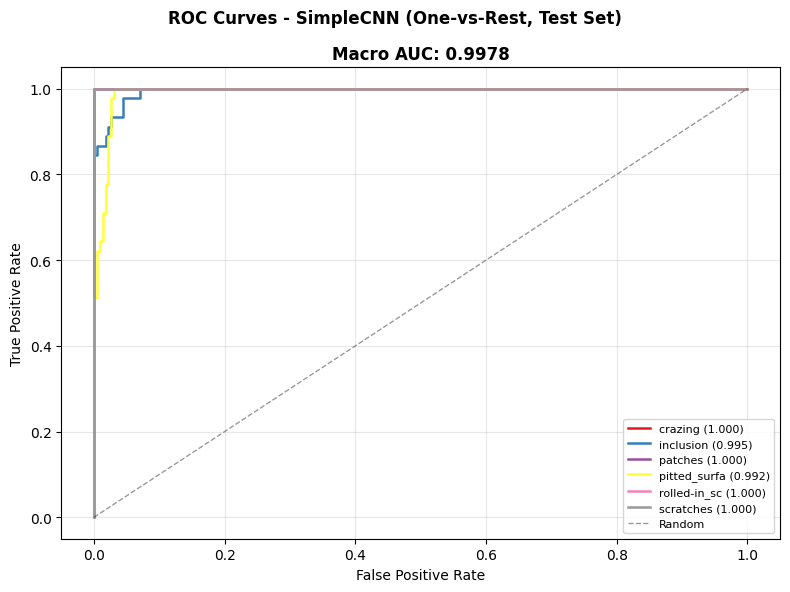

In [18]:
# 7.4 ROC Curves
fig, ax = plt.subplots(figsize=(8, 6))
fig.suptitle('ROC Curves - SimpleCNN (One-vs-Rest, Test Set)', fontsize=12, fontweight='bold')

class_colors = plt.cm.Set1(np.linspace(0, 1, NUM_CLASSES))
labels_bin   = label_binarize(cnn_metrics['labels'], classes=list(range(NUM_CLASSES)))

for i, (cls, cc) in enumerate(zip(CLASSES, class_colors)):
    fpr, tpr, _ = roc_curve(labels_bin[:, i], cnn_metrics['probs'][:, i], drop_intermediate=False)
    auc_i = roc_auc_score(labels_bin[:, i], cnn_metrics['probs'][:, i])
    ax.plot(fpr, tpr, color=cc, lw=1.8, label=f'{cls[:12]} ({auc_i:.3f})')

ax.plot([0,1],[0,1],'k--', lw=1, alpha=0.4, label='Random')
ax.set_title(f'Macro AUC: {cnn_metrics["roc_auc"]:.4f}', fontweight='bold')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.legend(fontsize=8, loc='lower right'); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/content/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [19]:
# 7.5 Classification Report
print('SimpleCNN - Classification Report')
print('-'*55)
print(classification_report(cnn_metrics['labels'], cnn_metrics['preds'], target_names=CLASSES))

SimpleCNN - Classification Report
-------------------------------------------------------
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        45
      inclusion       0.95      0.87      0.91        45
        patches       1.00      1.00      1.00        45
 pitted_surface       0.88      0.98      0.93        45
rolled-in_scale       1.00      1.00      1.00        45
      scratches       1.00      0.98      0.99        45

       accuracy                           0.97       270
      macro avg       0.97      0.97      0.97       270
   weighted avg       0.97      0.97      0.97       270



## Section 7.5 – EfficientNetB0 Transfer Learning

We now benchmark a **pretrained EfficientNetB0** backbone (ImageNet weights, TensorFlow/Keras) against our SimpleCNN trained from scratch.

### Strategy — Two-Phase Training
| Phase | Base model | Learning rate | Epochs |
|-------|-----------|--------------|--------|
| 1 – Head only | Frozen (all layers fixed) | 1e-3 | up to 20 |
| 2 – Fine-tune | Top ~40 layers unfrozen | 1e-5 | up to 15 |

### Why EfficientNetB0?
- Compound-scaled architecture that balances depth, width, and resolution.
- Only ~5.3M params but ImageNet top-1 accuracy of ~77%.
- EfficientNet family consistently outperforms comparable-sized CNNs on small datasets when fine-tuned.

### Integration notes
- All PyTorch training (SimpleCNN) is complete; we reuse `df_train / df_val / df_test`, `CLASSES`, `NUM_CLASSES`, and `SEED`.
- A separate `tf.data` pipeline is built — completely independent of the existing Albumentations/PyTorch loaders.
- New variable names are prefixed `eff_*` to avoid any collision with existing variables.

In [20]:
# ── 7.5.0  TF Setup + GPU Memory Hygiene ──────────────────────────────────────
# Free PyTorch's CUDA allocations so TensorFlow can share the T4 safely.
import torch as _torch
if _torch.cuda.is_available():
    _torch.cuda.empty_cache()
    print(f'PyTorch CUDA cache freed. Remaining allocated: '
          f'{_torch.cuda.memory_allocated()/1e6:.1f} MB')

import tensorflow as tf

# Enable memory growth so TF only takes what it needs (doesn't pre-allocate 15 GB)
for _gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(_gpu, True)

# Determinism
tf.keras.utils.set_random_seed(SEED)

print(f'TensorFlow version : {tf.__version__}')
print(f'Visible GPUs       : {tf.config.list_physical_devices("GPU")}')
print(f'Reusing from notebook — NUM_CLASSES={NUM_CLASSES}, CLASSES={CLASSES}')
print('TF setup complete.')

PyTorch CUDA cache freed. Remaining allocated: 35.3 MB
TensorFlow version : 2.20.0
Visible GPUs       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Reusing from notebook — NUM_CLASSES=6, CLASSES=['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
TF setup complete.


### 7.5.1 – Build `tf.data` Pipelines

We construct three `tf.data.Dataset` objects directly from the existing Pandas DataFrames (`df_train`, `df_val`, `df_test`) that were built earlier in Section 1.

- Images are decoded from disk, resized to **224×224** (EfficientNetB0's native input size), and preprocessed with `tf.keras.applications.efficientnet.preprocess_input` which scales pixels to `[-1, 1]`.
- Training pipeline adds lightweight on-the-fly augmentation (random H/V flips, random rotation) **independently** of the existing Albumentations pipeline — no existing code is touched.
- All label values are integer indices (`label_idx`) matching the existing `CLASS_TO_IDX` mapping, so `sparse_categorical_crossentropy` is the correct loss.

In [21]:
# ── 7.5.1  tf.data Pipelines (reuse existing DataFrames) ─────────────────────
IMG_SIZE_EFF   = 224
BATCH_SIZE_EFF = 32

def _load_and_preprocess(path, label):
    """Decode JPEG → resize → EfficientNet preprocess."""
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE_EFF, IMG_SIZE_EFF])
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def _augment(img, label):
    """Light augmentation for training only (independent of Albumentations pipeline)."""
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    # Random rotation ±15° via tfa-free approach using tf.keras layer applied on batch
    img = tf.image.rot90(img, k=tf.random.uniform((), 0, 4, dtype=tf.int32))
    return img, label

def make_tf_ds(df, training: bool) -> tf.data.Dataset:
    """Build a tf.data pipeline from an existing pandas DataFrame."""
    paths  = df['path'].values.tolist()
    labels = df['label_idx'].values.tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(_augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE_EFF).prefetch(tf.data.AUTOTUNE)
    return ds

eff_train_ds = make_tf_ds(df_train, training=True)
eff_val_ds   = make_tf_ds(df_val,   training=False)
eff_test_ds  = make_tf_ds(df_test,  training=False)

# Sanity check
for _imgs, _labels in eff_train_ds.take(1):
    print(f'Train batch — images: {_imgs.shape}  dtype: {_imgs.dtype}')
    print(f'             labels : {_labels.shape}  dtype: {_labels.dtype}')
    print(f'             pixel range: [{_imgs.numpy().min():.2f}, {_imgs.numpy().max():.2f}]')

print(f'\neff_train_ds batches : {len(eff_train_ds)}')
print(f'eff_val_ds   batches : {len(eff_val_ds)}')
print(f'eff_test_ds  batches : {len(eff_test_ds)}')
print('tf.data pipelines ready.')

Train batch — images: (32, 224, 224, 3)  dtype: <dtype: 'float32'>
             labels : (32,)  dtype: <dtype: 'int32'>
             pixel range: [0.00, 255.00]

eff_train_ds batches : 40
eff_val_ds   batches : 9
eff_test_ds  batches : 9
tf.data pipelines ready.


### 7.5.2 – EfficientNetB0 Model Architecture

```
Input (224×224×3)
    └─ EfficientNetB0 backbone (ImageNet weights, FROZEN in Phase 1)
           └─ GlobalAveragePooling2D        → (1280,)
                  └─ Dropout(0.3)
                         └─ Dense(256, relu)
                                └─ Dropout(0.3)
                                       └─ Dense(NUM_CLASSES, softmax)
```

- `include_top=False` removes EfficientNetB0's original 1000-class head.
- `training=False` passed to the base ensures BatchNorm layers stay in inference mode during Phase 1 — critical for stable transfer learning on small datasets.
- `NUM_CLASSES` is read directly from the existing notebook variable (6 classes auto-detected).

In [22]:
# ── 7.5.2  Build EfficientNetB0 Model ────────────────────────────────────────
# NUM_CLASSES is auto-detected from the existing notebook variable (set in Section 1)

eff_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE_EFF, IMG_SIZE_EFF, 3)
)
eff_base.trainable = False  # Phase 1: freeze entire backbone

# Custom classification head
_inputs  = tf.keras.Input(shape=(IMG_SIZE_EFF, IMG_SIZE_EFF, 3), name='input_image')
_x       = eff_base(_inputs, training=False)          # keep BN in inference mode
_x       = tf.keras.layers.GlobalAveragePooling2D(name='gap')(_x)
_x       = tf.keras.layers.Dropout(0.3, name='dropout_1')(_x)
_x       = tf.keras.layers.Dense(256, activation='relu', name='fc_256')(_x)
_x       = tf.keras.layers.Dropout(0.3, name='dropout_2')(_x)
_outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(_x)

eff_model = tf.keras.Model(inputs=_inputs, outputs=_outputs, name='EfficientNetB0_TL')

# Parameter counts
_total    = eff_model.count_params()
_trainable = sum(tf.size(w).numpy() for w in eff_model.trainable_weights)
print(f'Total parameters    : {_total:,}')
print(f'Trainable (Phase 1) : {_trainable:,}')
print(f'Frozen backbone     : {_total - _trainable:,}')
print()
eff_model.summary(line_length=90)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters    : 4,379,049
Trainable (Phase 1) : 329,478
Frozen backbone     : 4,049,571



Model: "EfficientNetB0_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)              │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)           │ (None, 7, 7, 1280)           │       4,049,571 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ gap (GlobalAveragePooling2D)          │ (None, 1280)                 │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                   │ (None, 1280)                 │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ fc_256 (Dense)                        │ (None, 256)                  │         327,936 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                   │ (None, 256)                  │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ predictions (Dense)                   │ (None, 6)                    │           1,542 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 4,379,049 (16.70 MB)

 Trainable params: 329,478 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

### 7.5.3 – Phase 1: Train Classification Head (Frozen Backbone)

Only the 4 newly added layers (Dense + Dropout head) are trainable.  
The entire EfficientNetB0 backbone stays frozen — its ImageNet features are used as fixed feature extractors.

**Callbacks:**
- `EarlyStopping` — stops training if `val_loss` does not improve for 5 consecutive epochs; restores best weights automatically.
- `ReduceLROnPlateau` — halves the learning rate if `val_loss` plateaus for 3 epochs (minimum LR = 1e-6).
- `ModelCheckpoint` — saves the epoch with the highest `val_accuracy` to disk.

In [23]:
# ── 7.5.3  Phase 1 – Compile + Train (Frozen Backbone) ───────────────────────
import time as _time

eff_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

_ckpt_p1 = '/content/efficientnetb0_best.keras'
_callbacks_p1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.3, patience=3,
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=_ckpt_p1, monitor='val_accuracy',
        save_best_only=True, verbose=1
    ),
]

print('='*60)
print('  EfficientNetB0 – Phase 1: Training head (frozen backbone)')
print('='*60)

_t0 = _time.time()
eff_history_phase1 = eff_model.fit(
    eff_train_ds,
    validation_data=eff_val_ds,
    epochs=20,
    callbacks=_callbacks_p1,
    verbose=1
)
print(f'\nPhase 1 complete in {(_time.time()-_t0)/60:.1f} min')
print(f'Best val_accuracy: {max(eff_history_phase1.history["val_accuracy"])*100:.2f}%')

  EfficientNetB0 – Phase 1: Training head (frozen backbone)
Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.6309 - loss: 1.0361
Epoch 1: val_accuracy improved from None to 0.99259, saving model to /content/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/efficientnetb0_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.8135 - loss: 0.5965 - val_accuracy: 0.9926 - val_loss: 0.0822 - learning_rate: 0.0010
Epoch 2/20
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9590 - loss: 0.1354
Epoch 2: val_accuracy did not improve from 0.99259
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.9611 - loss: 0.1227 - val_accuracy: 0.9926 - val_loss: 0.0401 - learning_rate: 0.0010
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9812 - loss: 0.0803
Epoch 3: val_accuracy improved from 0.99259 to 0.99630, saving model to /content/efficientnetb0_best.keras

Epoch 3: finished saving model to /content/efficientnetb0_best.keras
40/

### 7.5.4 – Phase 2: Fine-Tune Top Layers

After the classification head has converged, we unfreeze the **top ~40 layers** of the backbone and train the whole model end-to-end with a much lower learning rate (1e-5) to gently adjust the higher-level EfficientNet features to the steel defect domain.

Key points:
- Layers before the last 40 remain frozen — this preserves general low-level ImageNet features (edges, textures) while allowing domain-specific adaptation in higher layers.
- The model is recompiled with `Adam(1e-5)` — a 100× smaller LR than Phase 1 to avoid destroying the pretrained weights.
- A new `ModelCheckpoint` saves the fine-tuned best model separately so both checkpoints are available for comparison.

In [24]:
# ── 7.5.4  Phase 2 – Fine-Tune Top Layers ────────────────────────────────────
# Unfreeze the backbone, then re-freeze all but the last 40 layers
eff_base.trainable = True
for _layer in eff_base.layers[:-40]:
    _layer.trainable = False

_unfrozen = sum(1 for l in eff_base.layers if l.trainable)
print(f'Unfrozen backbone layers : {_unfrozen} / {len(eff_base.layers)}')
_trainable_p2 = sum(tf.size(w).numpy() for w in eff_model.trainable_weights)
print(f'Trainable parameters now : {_trainable_p2:,}')

eff_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

_ckpt_p2 = '/content/efficientnetb0_finetuned.keras'
_callbacks_p2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.3, patience=3,
        min_lr=1e-7, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=_ckpt_p2, monitor='val_accuracy',
        save_best_only=True, verbose=1
    ),
]

print('\n' + '='*60)
print('  EfficientNetB0 – Phase 2: Fine-tuning top 40 layers')
print('='*60)

_t0 = _time.time()
eff_history_phase2 = eff_model.fit(
    eff_train_ds,
    validation_data=eff_val_ds,
    epochs=15,
    callbacks=_callbacks_p2,
    verbose=1
)
print(f'\nPhase 2 complete in {(_time.time()-_t0)/60:.1f} min')
print(f'Best val_accuracy (Phase 2): {max(eff_history_phase2.history["val_accuracy"])*100:.2f}%')
print(f'Fine-tuned model saved to: {_ckpt_p2}')

Unfrozen backbone layers : 40 / 238
Trainable parameters now : 2,380,182

  EfficientNetB0 – Phase 2: Fine-tuning top 40 layers
Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 495ms/step - accuracy: 0.7654 - loss: 0.7088
Epoch 1: val_accuracy improved from None to 1.00000, saving model to /content/efficientnetb0_finetuned.keras

Epoch 1: finished saving model to /content/efficientnetb0_finetuned.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 65s 839ms/step - accuracy: 0.7738 - loss: 0.6757 - val_accuracy: 1.0000 - val_loss: 0.0056 - learning_rate: 1.0000e-05
Epoch 2/15
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8176 - loss: 0.5426
Epoch 2: val_accuracy did not improve from 1.00000
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.8317 - loss: 0.5027 - val_accuracy: 0.9963 - val_loss: 0.0114 - learning_rate: 1.0000e-05
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8842 - loss: 0.3908
Epoch 3: val_accuracy did not improve from 1.00000
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step 

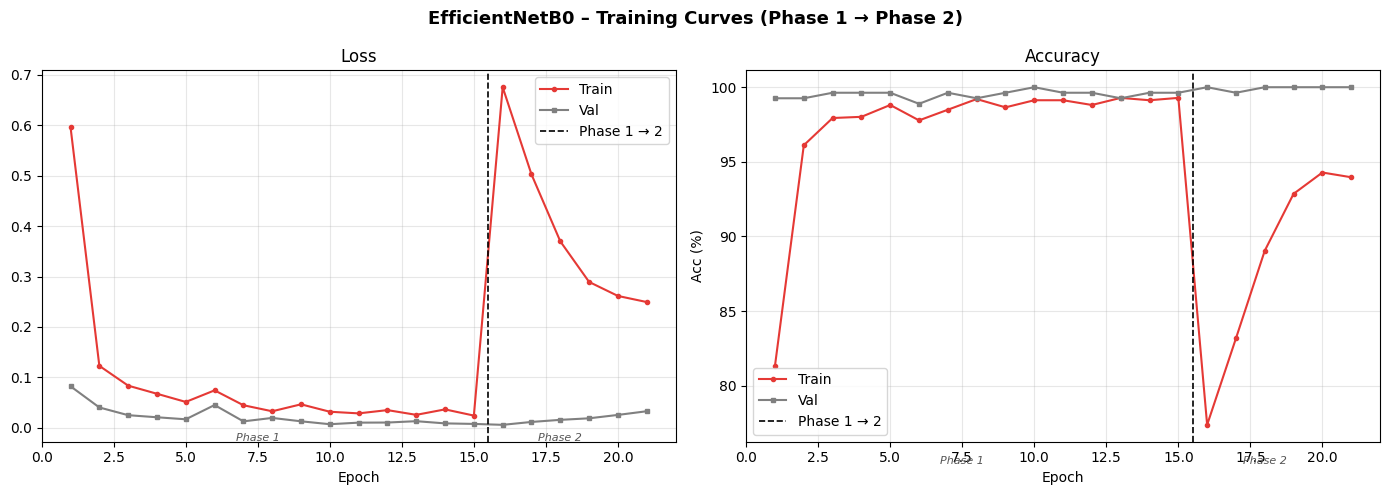

Curves saved → /content/efficientnetb0_curves.png
Phase 1 best val_acc : 100.00%
Phase 2 best val_acc : 100.00%
Δ from fine-tuning   : +0.00pp


In [25]:
# ── 7.5.5  Training Curves – Phase 1 + Phase 2 Stitched ──────────────────────
import matplotlib.pyplot as plt
import numpy as np

_h1_loss     = eff_history_phase1.history['loss']
_h1_val_loss = eff_history_phase1.history['val_loss']
_h1_acc      = eff_history_phase1.history['accuracy']
_h1_val_acc  = eff_history_phase1.history['val_accuracy']

_h2_loss     = eff_history_phase2.history['loss']
_h2_val_loss = eff_history_phase2.history['val_loss']
_h2_acc      = eff_history_phase2.history['accuracy']
_h2_val_acc  = eff_history_phase2.history['val_accuracy']

_all_loss     = _h1_loss     + _h2_loss
_all_val_loss = _h1_val_loss + _h2_val_loss
_all_acc      = _h1_acc      + _h2_acc
_all_val_acc  = _h1_val_acc  + _h2_val_acc

_n1   = len(_h1_loss)
_n    = len(_all_loss)
_eps  = range(1, _n + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('EfficientNetB0 – Training Curves (Phase 1 → Phase 2)', fontsize=13, fontweight='bold')

# Loss
axes[0].plot(_eps, _all_loss,     '-o', markersize=3, color='#E53935', label='Train')
axes[0].plot(_eps, _all_val_loss, '-s', markersize=3, color='gray',    label='Val')
axes[0].axvline(x=_n1 + 0.5, color='black', linestyle='--', linewidth=1.2, label='Phase 1 → 2')
axes[0].set_title('Loss');  axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(_eps, [a*100 for a in _all_acc],     '-o', markersize=3, color='#E53935', label='Train')
axes[1].plot(_eps, [a*100 for a in _all_val_acc], '-s', markersize=3, color='gray',    label='Val')
axes[1].axvline(x=_n1 + 0.5, color='black', linestyle='--', linewidth=1.2, label='Phase 1 → 2')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Acc (%)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Phase labels
for ax in axes:
    ax.text(_n1 / 2,        ax.get_ylim()[0] * 0.98, 'Phase 1', ha='center',
            fontsize=8, color='#555', style='italic')
    ax.text(_n1 + (_n - _n1) / 2, ax.get_ylim()[0] * 0.98, 'Phase 2', ha='center',
            fontsize=8, color='#555', style='italic')

plt.tight_layout()
plt.savefig('/content/efficientnetb0_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Curves saved → /content/efficientnetb0_curves.png')
print(f'Phase 1 best val_acc : {max(_h1_val_acc)*100:.2f}%')
print(f'Phase 2 best val_acc : {max(_h2_val_acc)*100:.2f}%')
print(f'Δ from fine-tuning   : {(max(_h2_val_acc) - max(_h1_val_acc))*100:+.2f}pp')

### 7.5.6 – Test Set Evaluation

Evaluate the fine-tuned EfficientNetB0 on the held-out test set (270 images, same split as SimpleCNN).  
We build the same `eff_metrics` dict structure as `cnn_metrics` so the comparison cell can reference both uniformly.

In [26]:
# ── 7.5.6  Test Set Evaluation ───────────────────────────────────────────────
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize

# Keras evaluate
print('Evaluating on test set...')
_test_loss, _test_acc = eff_model.evaluate(eff_test_ds, verbose=0)

# Collect predictions + probabilities
eff_preds_list  = []
eff_labels_list = []
eff_probs_list  = []

for _imgs_b, _labels_b in eff_test_ds:
    _probs_b = eff_model(_imgs_b, training=False).numpy()
    eff_probs_list.append(_probs_b)
    eff_preds_list.append(np.argmax(_probs_b, axis=1))
    eff_labels_list.append(_labels_b.numpy())

eff_preds  = np.concatenate(eff_preds_list)
eff_labels = np.concatenate(eff_labels_list)
eff_probs  = np.concatenate(eff_probs_list)

# Compute metrics matching cnn_metrics structure
_labels_bin = label_binarize(eff_labels, classes=list(range(NUM_CLASSES)))
_roc_auc    = roc_auc_score(_labels_bin, eff_probs, multi_class='ovr', average='macro')
_f1_mac     = f1_score(eff_labels, eff_preds, average='macro')
_f1_wt      = f1_score(eff_labels, eff_preds, average='weighted')

eff_metrics = {
    'accuracy':    _test_acc,
    'f1_macro':    _f1_mac,
    'f1_weighted': _f1_wt,
    'roc_auc':     _roc_auc,
    'preds':       eff_preds,
    'labels':      eff_labels,
    'probs':       eff_probs,
}

print('='*55)
print('  EfficientNetB0 – TEST SET RESULTS')
print('='*55)
print(f'  Accuracy   : {_test_acc*100:.2f}%')
print(f'  Macro F1   : {_f1_mac*100:.2f}%')
print(f'  Weighted F1: {_f1_wt*100:.2f}%')
print(f'  ROC-AUC    : {_roc_auc:.4f}')
print('='*55)

Evaluating on test set...
  EfficientNetB0 – TEST SET RESULTS
  Accuracy   : 98.89%
  Macro F1   : 98.88%
  Weighted F1: 98.88%
  ROC-AUC    : 1.0000


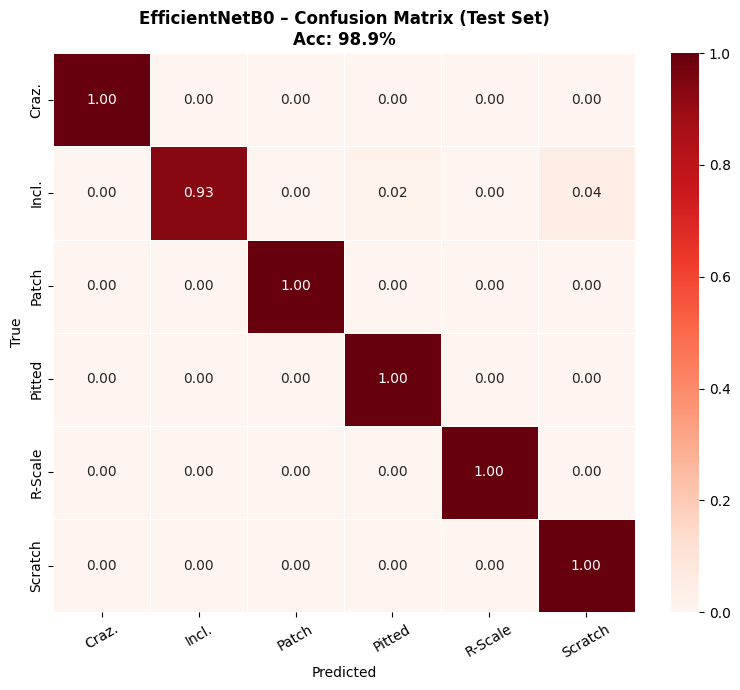

Confusion matrix saved → /content/efficientnetb0_confusion_matrix.png

EfficientNetB0 – Classification Report
-------------------------------------------------------
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        45
      inclusion       1.00      0.93      0.97        45
        patches       1.00      1.00      1.00        45
 pitted_surface       0.98      1.00      0.99        45
rolled-in_scale       1.00      1.00      1.00        45
      scratches       0.96      1.00      0.98        45

       accuracy                           0.99       270
      macro avg       0.99      0.99      0.99       270
   weighted avg       0.99      0.99      0.99       270



In [27]:
# ── 7.5.7  Confusion Matrix + Classification Report ──────────────────────────
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Label abbreviations (self-contained so this cell does not depend on Cell 25)
_ABBREV = {
    'crazing':        'Craz.',
    'inclusion':      'Incl.',
    'patches':        'Patch',
    'pitted_surface': 'Pitted',
    'rolled-in_scale':'R-Scale',
    'scratches':      'Scratch',
}
_short_labels = [_ABBREV.get(c, c[:7]) for c in CLASSES]

fig, ax = plt.subplots(figsize=(8, 7))
_cm      = confusion_matrix(eff_metrics['labels'], eff_metrics['preds'])
_cm_norm = _cm.astype(float) / _cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(_cm_norm, annot=True, fmt='.2f', cmap='Reds', ax=ax,
            xticklabels=_short_labels, yticklabels=_short_labels,
            cbar=True, linewidths=0.5)
ax.set_title(
    f'EfficientNetB0 – Confusion Matrix (Test Set)\nAcc: {eff_metrics["accuracy"]*100:.1f}%',
    fontweight='bold')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('/content/efficientnetb0_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Confusion matrix saved → /content/efficientnetb0_confusion_matrix.png')

print('\nEfficientNetB0 – Classification Report')
print('-'*55)
print(classification_report(eff_metrics['labels'], eff_metrics['preds'], target_names=CLASSES))

### 7.5.8 – Model Comparison: SimpleCNN vs EfficientNetB0

Head-to-head comparison of both models on the **same 270-image test set**:

| Metric | SimpleCNN (scratch) | EfficientNetB0 (TL) | Δ |
|--------|--------------------|--------------------|---|
| Test Accuracy | ? | ? | ? |
| Macro F1 | ? | ? | ? |
| Weighted F1 | ? | ? | ? |
| ROC-AUC | ? | ? | ? |

*(Values filled in automatically by the cell below)*

  Metric                 SimpleCNN  EfficientNetB0         Δ
-----------------------------------------------------------------
  Test Accuracy             97.04%          98.89%   +1.85pp
  Macro F1                  97.03%          98.88%   +1.85pp
  Weighted F1               97.03%          98.88%   +1.85pp
  ROC-AUC                   0.9978          1.0000   +0.0022


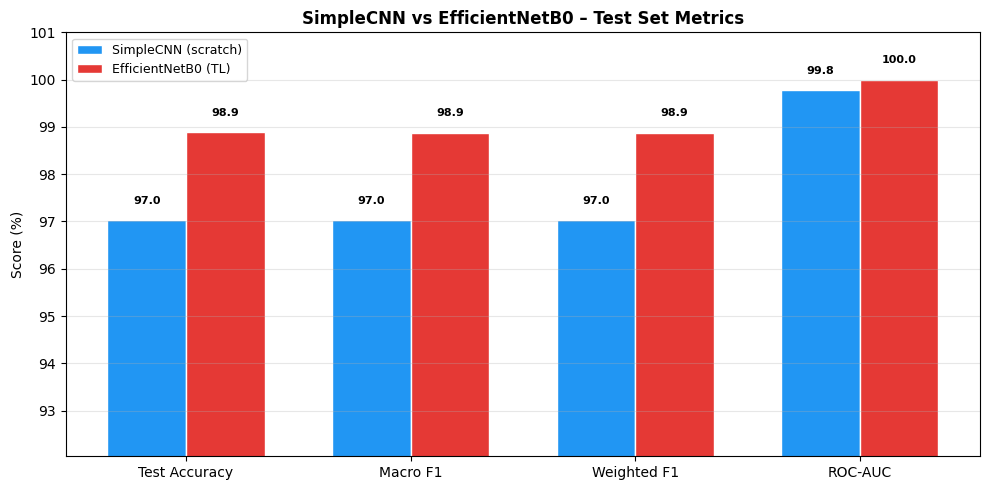

Comparison chart saved → /content/model_comparison.png

Verdict: EfficientNetB0 wins on accuracy by 1.85 percentage points.


In [28]:
# ── 7.5.8  SimpleCNN vs EfficientNetB0 – Side-by-side Comparison ─────────────
import matplotlib.pyplot as plt
import numpy as np

_metrics_keys   = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc']
_metric_labels  = ['Test Accuracy', 'Macro F1', 'Weighted F1', 'ROC-AUC']

_cnn_vals = [cnn_metrics[k] for k in _metrics_keys]
_eff_vals = [eff_metrics[k] for k in _metrics_keys]

print('='*65)
print(f'  {"Metric":<18}  {"SimpleCNN":>12}  {"EfficientNetB0":>14}  {"Δ":>8}')
print('-'*65)
for label, cv, ev in zip(_metric_labels, _cnn_vals, _eff_vals):
    delta = (ev - cv) * 100
    unit  = '' if label == 'ROC-AUC' else '%'
    cv_s  = f'{cv*100:.2f}%' if unit == '%' else f'{cv:.4f}'
    ev_s  = f'{ev*100:.2f}%' if unit == '%' else f'{ev:.4f}'
    d_s   = f'{delta:+.2f}pp' if unit == '%' else f'{delta/100:+.4f}'
    print(f'  {label:<18}  {cv_s:>12}  {ev_s:>14}  {d_s:>8}')
print('='*65)

# Bar chart
fig, ax = plt.subplots(figsize=(10, 5))
_x       = np.arange(len(_metric_labels))
_width   = 0.35

_bars1 = ax.bar(_x - _width/2, [v*100 for v in _cnn_vals], _width,
                label='SimpleCNN (scratch)', color='#2196F3', edgecolor='white')
_bars2 = ax.bar(_x + _width/2, [v*100 for v in _eff_vals], _width,
                label='EfficientNetB0 (TL)',  color='#E53935', edgecolor='white')

for bar in list(_bars1) + list(_bars2):
    _h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, _h + 0.3,
            f'{_h:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(_x)
ax.set_xticklabels(_metric_labels, fontsize=10)
ax.set_ylabel('Score (%)')
ax.set_ylim([max(0, min(_cnn_vals + _eff_vals)*100 - 5), 101])
ax.set_title('SimpleCNN vs EfficientNetB0 – Test Set Metrics',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Comparison chart saved → /content/model_comparison.png')

# Verdict
_winner = 'EfficientNetB0' if eff_metrics['accuracy'] > cnn_metrics['accuracy'] else 'SimpleCNN'
_delta_acc = abs(eff_metrics['accuracy'] - cnn_metrics['accuracy']) * 100
print(f'\nVerdict: {_winner} wins on accuracy by {_delta_acc:.2f} percentage points.')

## Section 8 – Grad-CAM Visualisation

Grad-CAM (Gradient-weighted Class Activation Mapping) highlights which spatial regions of each steel image the **SimpleCNN** focuses on when making a prediction.

We hook into the **last convolutional layer** (`features[-1]`) of our custom CNN — no pretrained backbone needed. The heatmap shows which pixels influenced the decision most.

In [29]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# The last conv layer in our SimpleCNN is the final block of self.features
# Each block ends with MaxPool2d, so the last conv is inside features[-1][-3]
# (Conv2d at index -3 inside the last Sequential block)
target_layer = [cnn_model.features[-1][-3]]

cam_engine = GradCAM(model=cnn_model, target_layers=target_layer)
print('Grad-CAM engine attached to:', target_layer[0].__class__.__name__)
cnn_model.eval()
print('Model set to eval mode.')

Grad-CAM engine attached to: BatchNorm2d
Model set to eval mode.


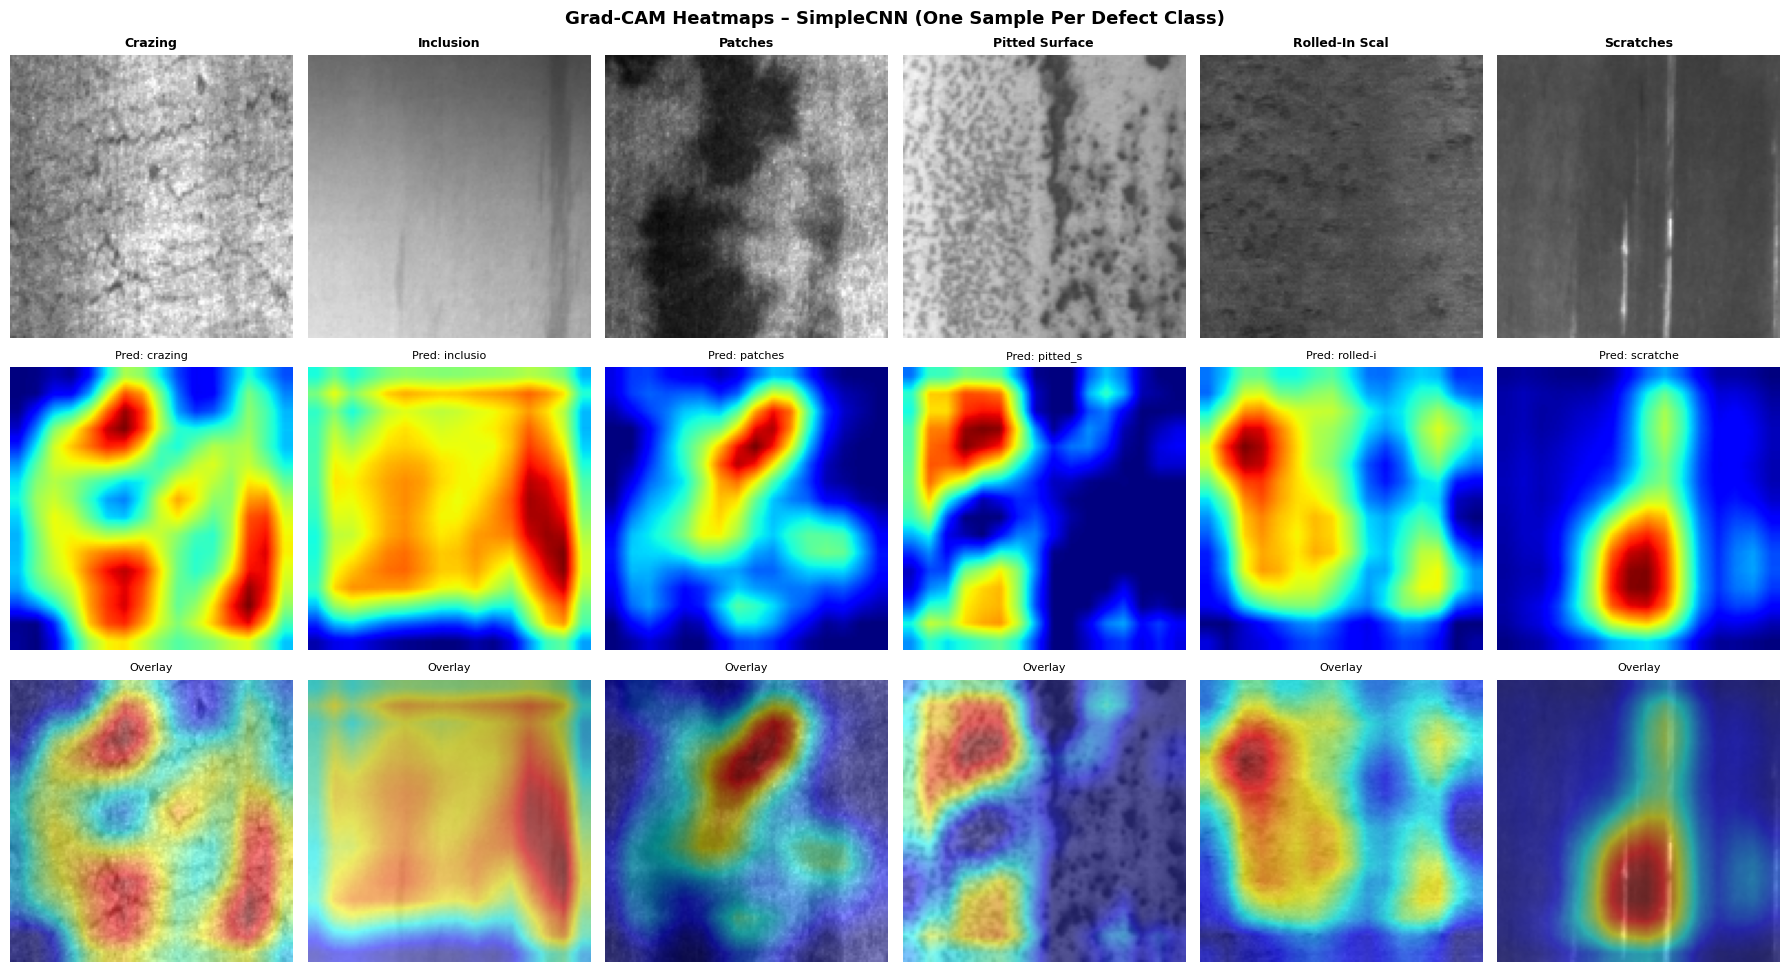

Grad-CAM saved to /content/gradcam_results.png


In [30]:
# ── Grad-CAM: one image per defect class ──
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(18, 10))
fig.suptitle('Grad-CAM Heatmaps – SimpleCNN (One Sample Per Defect Class)',
             fontsize=13, fontweight='bold')

for col, cls in enumerate(CLASSES):
    # pick one test sample from this class
    row_df  = df_test[df_test['label'] == cls].sample(1, random_state=SEED).iloc[0]
    raw_img = np.array(Image.open(row_df['path']).convert('RGB'))
    raw_img = cv2.resize(raw_img, (IMG_SIZE, IMG_SIZE))

    # prepare tensor
    tensor = val_test_transforms(image=raw_img.copy())['image'].unsqueeze(0).to(DEVICE)

    # get predicted class
    with torch.no_grad():
        pred_idx = cnn_model(tensor).argmax().item()

    # compute Grad-CAM for the true class
    targets       = [ClassifierOutputTarget(int(row_df['label_idx']))]
    grayscale_cam = cam_engine(input_tensor=tensor, targets=targets)[0]

    # overlay
    rgb_norm = raw_img.astype(float) / 255.0
    cam_img  = show_cam_on_image(rgb_norm, grayscale_cam, use_rgb=True)

    # plot
    axes[0, col].imshow(raw_img)
    axes[0, col].set_title(cls.replace('_', ' ').title()[:14], fontsize=9, fontweight='bold')
    axes[0, col].axis('off')

    axes[1, col].imshow(grayscale_cam, cmap='jet')
    axes[1, col].set_title(f'Pred: {CLASSES[pred_idx][:8]}', fontsize=8)
    axes[1, col].axis('off')

    axes[2, col].imshow(cam_img)
    axes[2, col].set_title('Overlay', fontsize=8)
    axes[2, col].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=9)
axes[1, 0].set_ylabel('Heatmap', fontsize=9)
axes[2, 0].set_ylabel('Overlay', fontsize=9)
plt.tight_layout()
plt.savefig('/content/gradcam_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grad-CAM saved to /content/gradcam_results.png')

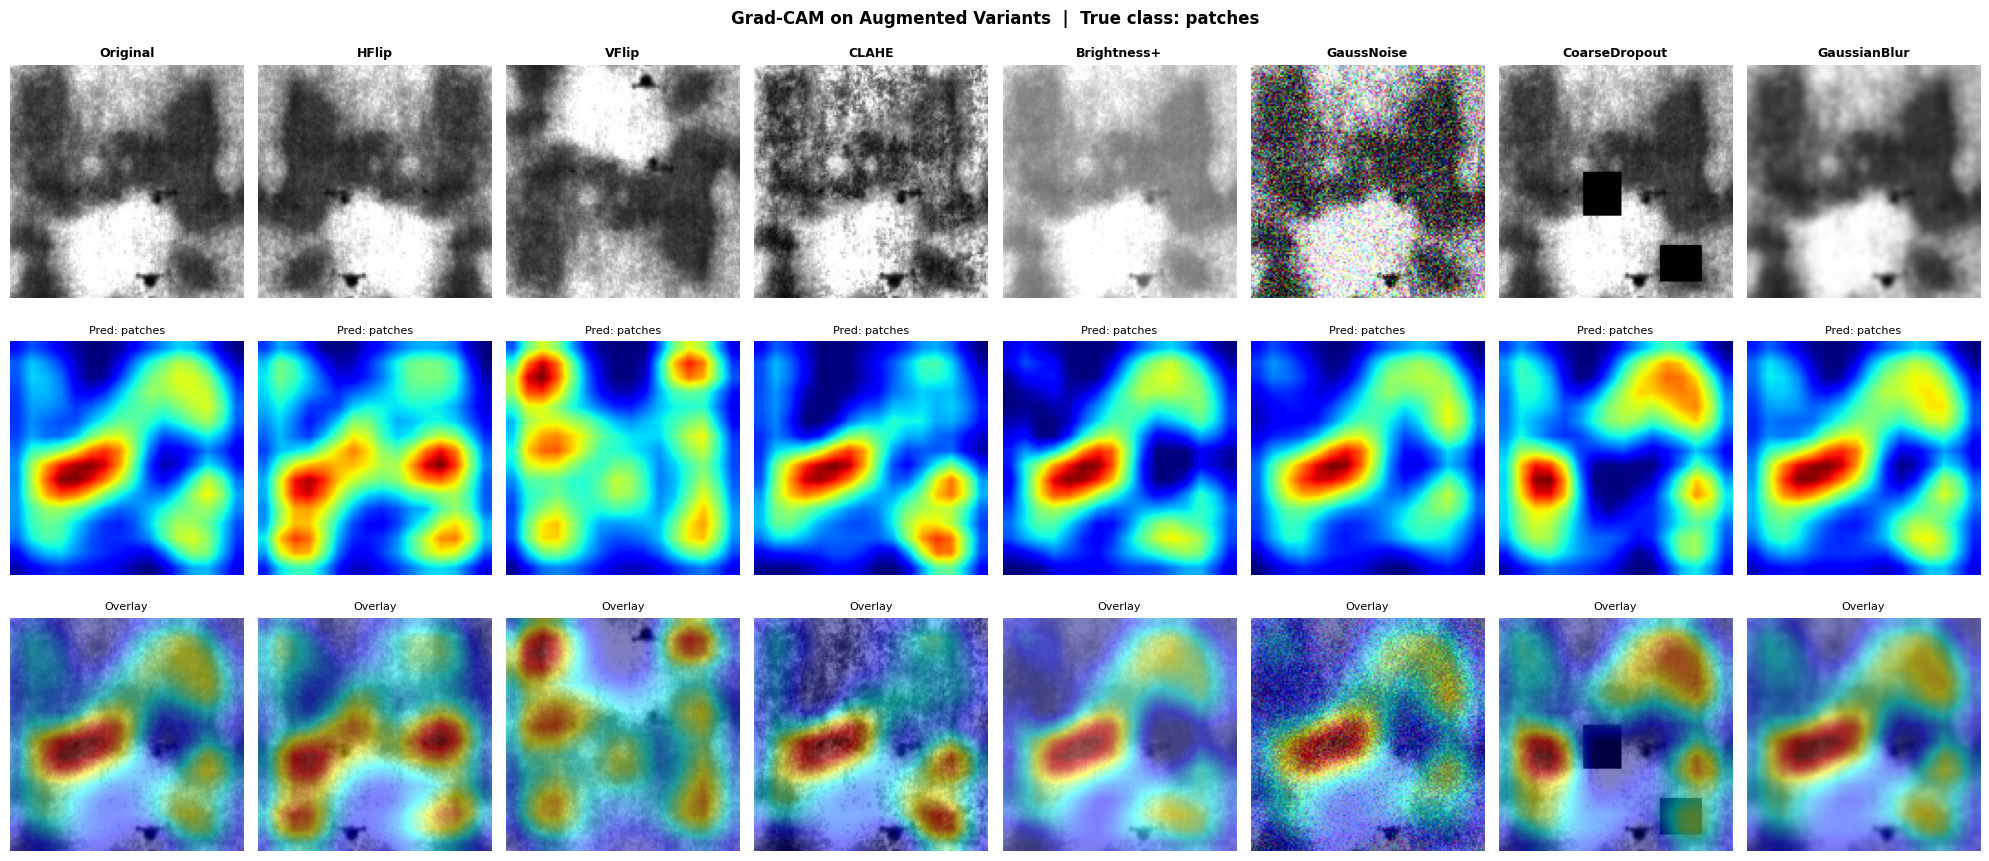

Augmented Grad-CAM saved to /content/gradcam_augmented.png


In [31]:
# ── Grad-CAM on Augmented Variants of One Image ──
# Shows how augmentations shift the model's attention
base_row = df_test.iloc[0]
base_raw = np.array(Image.open(base_row['path']).convert('RGB'))
base_raw = cv2.resize(base_raw, (IMG_SIZE, IMG_SIZE))

aug_variants = [
    ('Original',         None),
    ('HFlip',            A.HorizontalFlip(p=1)),
    ('VFlip',            A.VerticalFlip(p=1)),
    ('CLAHE',            A.CLAHE(clip_limit=6.0, p=1)),
    ('Brightness+',      A.RandomBrightnessContrast(0.5, 0.5, p=1)),
    ('GaussNoise',       A.GaussNoise(var_limit=(60,120), p=1)),
    ('CoarseDropout',    A.CoarseDropout(max_holes=10, max_height=18, max_width=18, p=1)),
    ('GaussianBlur',     A.GaussianBlur(blur_limit=(5, 9), p=1)),
]

fig, axes = plt.subplots(3, len(aug_variants), figsize=(20, 9))
fig.suptitle(
    f'Grad-CAM on Augmented Variants  |  True class: {base_row["label"]}',
    fontsize=12, fontweight='bold'
)

norm_aug = A.Compose([A.Normalize(mean=IMG_MEAN, std=IMG_STD), ToTensorV2()])

for col, (name, aug) in enumerate(aug_variants):
    if aug is not None:
        img_aug = aug(image=base_raw.copy())['image']
    else:
        img_aug = base_raw.copy()

    tensor = norm_aug(image=img_aug)['image'].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        pred_idx = cnn_model(tensor).argmax().item()

    targets       = [ClassifierOutputTarget(int(base_row['label_idx']))]
    grayscale_cam = cam_engine(input_tensor=tensor, targets=targets)[0]
    rgb_norm      = img_aug.astype(float) / 255.0
    cam_img       = show_cam_on_image(rgb_norm, grayscale_cam, use_rgb=True)

    axes[0, col].imshow(img_aug)
    axes[0, col].set_title(name, fontsize=9, fontweight='bold'); axes[0, col].axis('off')

    axes[1, col].imshow(grayscale_cam, cmap='jet')
    axes[1, col].set_title(f'Pred: {CLASSES[pred_idx][:7]}', fontsize=8); axes[1, col].axis('off')

    axes[2, col].imshow(cam_img)
    axes[2, col].set_title('Overlay', fontsize=8); axes[2, col].axis('off')

axes[0, 0].set_ylabel('Augmented', fontsize=9)
axes[1, 0].set_ylabel('Heatmap', fontsize=9)
axes[2, 0].set_ylabel('Overlay', fontsize=9)
plt.tight_layout()
plt.savefig('/content/gradcam_augmented.png', dpi=150, bbox_inches='tight')
plt.show()
print('Augmented Grad-CAM saved to /content/gradcam_augmented.png')

## Section 9 – Live Inspection Portal (Gradio)

A real-time web dashboard simulating a Tata Steel production line quality inspection system.

**Features:**
- Upload any steel image and get instant defect classification
- **Grad-CAM heatmap** overlay showing where the model is looking
- **Confidence bar chart** across all 6 classes
- 🎲 **Random sensor sample** button to pull from the test set
- Public shareable link via `share=True`

> Run the cell below — a Gradio link will appear. Click it to open the live portal.

In [32]:
import gradio as gr
import numpy as np
import cv2
from PIL import Image
import torch
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── ensure model is in eval mode ──
cnn_model.eval()

# ── Grad-CAM engine for the portal (reuse target layer) ──
portal_cam = GradCAM(model=cnn_model, target_layers=[cnn_model.features[-1][-3]])

IMAGENET_MEAN = IMG_MEAN
IMAGENET_STD  = IMG_STD

CLASS_COLORS = [
    '#E53935', '#8E24AA', '#1E88E5', '#00ACC1', '#43A047', '#F4511E'
]


def run_inference(pil_img):
    """Run the CNN + Grad-CAM on a PIL image. Returns overlay image + confidence figure."""
    img_np  = np.array(pil_img.convert('RGB'))
    img_res = cv2.resize(img_np, (IMG_SIZE, IMG_SIZE))

    # normalise
    norm    = A.Compose([A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])
    tensor  = norm(image=img_res)['image'].unsqueeze(0).to(DEVICE)

    # forward pass
    with torch.no_grad():
        logits = cnn_model(tensor)
        probs  = torch.softmax(logits, 1)[0].cpu().numpy()
    pred_idx  = int(probs.argmax())
    pred_cls  = CLASSES[pred_idx]
    conf      = float(probs[pred_idx])

    # Grad-CAM
    targets       = [ClassifierOutputTarget(pred_idx)]
    grayscale_cam = portal_cam(input_tensor=tensor, targets=targets)[0]
    rgb_norm      = img_res.astype(float) / 255.0
    cam_overlay   = show_cam_on_image(rgb_norm, grayscale_cam, use_rgb=True)

    # ── Confidence bar chart ──
    fig, ax = plt.subplots(figsize=(5, 3))
    bars = ax.barh(
        [c.replace('_', ' ') for c in CLASSES],
        probs * 100,
        color=CLASS_COLORS,
        edgecolor='white'
    )
    for bar, v in zip(bars, probs * 100):
        ax.text(min(v + 1, 99), bar.get_y() + bar.get_height() / 2,
                f'{v:.1f}%', va='center', fontsize=8, fontweight='bold')
    ax.set_xlim(0, 110)
    ax.set_xlabel('Confidence (%)')
    ax.set_title(f'Prediction: {pred_cls.upper()}  ({conf*100:.1f}%)',
                 fontweight='bold', fontsize=10)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    fig.tight_layout()

    alert = '🚨 DEFECT' if conf > 0.80 else ('⚠️  UNCERTAIN' if conf < 0.55 else '✅  DETECTED')
    status_text = (
        f'{alert}\n'
        f'Class   : {pred_cls.replace("_", " ").upper()}\n'
        f'Confidence: {conf*100:.1f}%\n'
        f'Rank 2  : {CLASSES[np.argsort(probs)[-2]].replace("_"," ")} ({np.sort(probs)[-2]*100:.1f}%)'
    )

    return Image.fromarray(cam_overlay), fig, status_text


def sensor_sample():
    """Pull a random image from the test set to simulate a sensor feed."""
    sample   = df_test.sample(1).iloc[0]
    pil_img  = Image.open(sample['path']).convert('RGB')
    cam, fig, status = run_inference(pil_img)
    sensor_info = f"[SENSOR] CAM-{random.randint(1,8):03d} | True label: {sample['label']}"
    return pil_img, cam, fig, status, sensor_info


def predict(pil_img):
    if pil_img is None:
        return None, None, 'No image uploaded.'
    return run_inference(pil_img)


# ── Build Gradio UI ──
with gr.Blocks(title='NEU-STEEL Live Inspection', theme=gr.themes.Soft()) as demo:
    gr.HTML(
        '<h1 style="text-align:center; color:#1565C0">🔩 NEU-STEEL Live Inspection Portal</h1>'
        '<p style="text-align:center; color:#555">SimpleCNN · Grad-CAM · 6 Defect Classes</p>'
    )

    with gr.Row():
        with gr.Column(scale=1):
            img_input    = gr.Image(type='pil', label='Upload Steel Image')
            sensor_label = gr.Textbox(label='Sensor Feed Info', interactive=False, lines=1)
            with gr.Row():
                btn_predict = gr.Button('🔍 Analyse', variant='primary')
                btn_sensor  = gr.Button('📡 Random Sensor Sample')
                btn_clear   = gr.Button('🗑 Clear')

        with gr.Column(scale=1):
            cam_output    = gr.Image(type='pil', label='Grad-CAM Heatmap Overlay')

        with gr.Column(scale=1):
            chart_output  = gr.Plot(label='Confidence per Class')
            status_output = gr.Textbox(label='Diagnosis', lines=5, interactive=False)

    # ── Event bindings ──
    btn_predict.click(
        fn=predict,
        inputs=[img_input],
        outputs=[cam_output, chart_output, status_output]
    )
    img_input.change(
        fn=predict,
        inputs=[img_input],
        outputs=[cam_output, chart_output, status_output]
    )
    btn_sensor.click(
        fn=sensor_sample,
        inputs=[],
        outputs=[img_input, cam_output, chart_output, status_output, sensor_label]
    )
    btn_clear.click(
        fn=lambda: (None, None, None, '', ''),
        outputs=[img_input, cam_output, chart_output, status_output, sensor_label]
    )

demo.launch(share=True, debug=False)
print('Portal launched. Click the public URL above to open the live portal.')

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://752b62d3cdb7dfe681.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Portal launched. Click the public URL above to open the live portal.


## Section 10 – Final Summary

In [33]:
print('='*60)
print('  NEU-STEEL - FINAL RESULTS (SimpleCNN)')
print('='*60)

print('\nDATASET')
print(f'  Source   : NEU-DET')
print(f'  Total    : {len(df_all)} images | {NUM_CLASSES} classes')
print(f'  Split    : 70/15/15 stratified')
print(f'  Img Size : {IMG_SIZE}x{IMG_SIZE}')

total_params = sum(p.numel() for p in cnn_model.parameters())
print(f'\nMODEL')
print(f'  Architecture : SimpleCNN (4 conv blocks, trained from scratch)')
print(f'  Parameters   : {total_params/1e6:.2f}M')
print(f'  Pretrained   : No')

print(f'\nRESULTS')
print(f'  Test Accuracy   : {cnn_metrics["accuracy"]*100:.2f}%')
print(f'  Macro F1        : {cnn_metrics["f1_macro"]*100:.2f}%')
print(f'  Weighted F1     : {cnn_metrics["f1_weighted"]*100:.2f}%')
print(f'  Macro ROC-AUC   : {cnn_metrics["roc_auc"]:.4f}')

print('\nEXTRAS')
print('  Grad-CAM per class   : /content/gradcam_results.png')
print('  Grad-CAM augmented   : /content/gradcam_augmented.png')
print('  Live portal          : Gradio (Section 9)')

print('\n' + '='*60)

  NEU-STEEL - FINAL RESULTS (SimpleCNN)

DATASET
  Source   : NEU-DET
  Total    : 1800 images | 6 classes
  Split    : 70/15/15 stratified
  Img Size : 128x128

MODEL
  Architecture : SimpleCNN (4 conv blocks, trained from scratch)
  Parameters   : 1.31M
  Pretrained   : No

RESULTS
  Test Accuracy   : 97.04%
  Macro F1        : 97.03%
  Weighted F1     : 97.03%
  Macro ROC-AUC   : 0.9978

EXTRAS
  Grad-CAM per class   : /content/gradcam_results.png
  Grad-CAM augmented   : /content/gradcam_augmented.png
  Live portal          : Gradio (Section 9)



In [34]:
# Download All Results
from google.colab import files

result_files = [
    '/content/augmentation_examples.png',
    '/content/training_curves.png',
    '/content/confusion_matrix.png',
    '/content/roc_curves.png',
    '/content/gradcam_results.png',
    '/content/gradcam_augmented.png',
    '/content/simplecnn_best.pth',
]

zip_out = '/content/NEU_STEEL_SimpleCNN_Results.zip'
missing, found = [], []
with zipfile.ZipFile(zip_out, 'w') as zf:
    for f in result_files:
        if os.path.exists(f):
            zf.write(f, os.path.basename(f))
            found.append(os.path.basename(f))
        else:
            missing.append(f)

print(f'Packed {len(found)} files')
if missing:
    print(f'Missing (run respective cells first): {missing}')

files.download(zip_out)
print(f'Downloaded: {os.path.getsize(zip_out)/1e6:.1f} MB')

Packed 7 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: 10.3 MB


---
## References

1. He, Y., et al. (2020). NEU surface defect database. *IEEE Trans. Instrumentation & Measurement*.
2. Buslaev, A., et al. (2020). Albumentations. *Information*, 11(2).

---
*Project – EST Evaluation | TIET | Custom CNN Steel Surface Defect Detection*